# 07 - MediaPipe Hand Landmark Exploration

## Objetivo

Visualizar lo que MediaPipe "ve" cuando procesa videos de lenguaje de signos.

En lugar de 224x224x3 = 150,528 valores de pixeles, MediaPipe extrae:
- 21 landmarks por mano
- Cada landmark tiene coordenadas (x, y, z)
- Total: 21 x 3 = **63 valores por mano por frame**

Este notebook sigue la **documentacion oficial de Google MediaPipe Tasks API**.

In [1]:
# Instalar MediaPipe si es necesario
%pip install -q mediapipe opencv-python numpy matplotlib


[notice] A new release of pip is available: 25.3 -> 26.0
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [2]:
# ==========================================
# 1. SETUP DE MEDIAPIPE (Tasks API Oficial)
# ==========================================
import mediapipe as mp
from mediapipe.tasks import python
from mediapipe.tasks.python import vision
import urllib.request
import os
import cv2
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

print(f"MediaPipe version: {mp.__version__}")

# Descargar modelo (si no existe)
model_path = "hand_landmarker.task"
if not os.path.exists(model_path):
    print("Descargando modelo hand_landmarker.task...")
    url = "https://storage.googleapis.com/mediapipe-models/hand_landmarker/hand_landmarker/float16/1/hand_landmarker.task"
    urllib.request.urlretrieve(url, model_path)
    print("Modelo descargado.")
else:
    print("Modelo ya existe.")

# Crear el detector (HandLandmarker) - EXACTO a documentacion Google
base_options = python.BaseOptions(model_asset_path=model_path)
options = vision.HandLandmarkerOptions(
    base_options=base_options,
    num_hands=2,
    min_hand_detection_confidence=0.3,
    min_hand_presence_confidence=0.3,
    min_tracking_confidence=0.3
)
detector = vision.HandLandmarker.create_from_options(options)
print("Detector inicializado correctamente.")

MediaPipe version: 0.10.32
Descargando modelo hand_landmarker.task...
Modelo descargado.
Detector inicializado correctamente.


INFO: Created TensorFlow Lite XNNPACK delegate for CPU.
W0000 00:00:1769875348.767743   95365 inference_feedback_manager.cc:114] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.
W0000 00:00:1769875348.777344   95379 inference_feedback_manager.cc:114] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.


In [3]:
# ==========================================
# 2. UTILIDADES DE VISUALIZACION (Oficial Google)
# ==========================================
# Codigo EXACTO del ejemplo oficial de MediaPipe Tasks
# https://colab.research.google.com/github/googlesamples/mediapipe/blob/main/examples/hand_landmarker/python/hand_landmarker.ipynb

mp_hands = mp.tasks.vision.HandLandmarksConnections
mp_drawing = mp.tasks.vision.drawing_utils
mp_drawing_styles = mp.tasks.vision.drawing_styles

MARGIN = 10  # pixels
FONT_SIZE = 1
FONT_THICKNESS = 1
HANDEDNESS_TEXT_COLOR = (88, 205, 54)  # vibrant green

def draw_landmarks_on_image(rgb_image, detection_result):
    """Dibuja landmarks en la imagen (funcion oficial de Google)."""
    hand_landmarks_list = detection_result.hand_landmarks
    handedness_list = detection_result.handedness
    annotated_image = np.copy(rgb_image)

    # Loop through the detected hands to visualize
    for idx in range(len(hand_landmarks_list)):
        hand_landmarks = hand_landmarks_list[idx]
        handedness = handedness_list[idx]

        # Draw the hand landmarks
        mp_drawing.draw_landmarks(
            annotated_image,
            hand_landmarks,
            mp_hands.HAND_CONNECTIONS,
            mp_drawing_styles.get_default_hand_landmarks_style(),
            mp_drawing_styles.get_default_hand_connections_style())

        # Get the top left corner of the detected hand's bounding box
        height, width, _ = annotated_image.shape
        x_coordinates = [landmark.x for landmark in hand_landmarks]
        y_coordinates = [landmark.y for landmark in hand_landmarks]
        text_x = int(min(x_coordinates) * width)
        text_y = int(min(y_coordinates) * height) - MARGIN

        # Draw handedness (left or right hand) on the image
        cv2.putText(annotated_image, f"{handedness[0].category_name}",
                    (text_x, text_y), cv2.FONT_HERSHEY_DUPLEX,
                    FONT_SIZE, HANDEDNESS_TEXT_COLOR, FONT_THICKNESS, cv2.LINE_AA)

    return annotated_image

print("Funciones de visualizacion cargadas (API oficial Google).")

Funciones de visualizacion cargadas (API oficial Google).


In [4]:
# ==========================================
# 3. CONFIGURACION DE RUTAS
# ==========================================

# Ruta a los videos MP4 originales (NO los frames procesados 224x224)
RAW_VIDEOS_DIR = Path("/home/fransando/Dev/tfg-sign-language-recognition/06_datasets/wlasl/raw/kaggle_wlasl/videos")

# Ruta para guardar resultados
OUTPUT_DIR = Path("/home/fransando/Dev/tfg-sign-language-recognition/05_experiments/mediapipe")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Verificar que existen los videos
if RAW_VIDEOS_DIR.exists():
    videos = list(RAW_VIDEOS_DIR.glob("*.mp4"))[:10]
    print(f"Encontrados {len(videos)} videos en {RAW_VIDEOS_DIR}")
    for v in videos[:5]:
        print(f"  - {v.name}")
else:
    print(f"ERROR: No se encuentra {RAW_VIDEOS_DIR}")

Encontrados 10 videos en /home/fransando/Dev/tfg-sign-language-recognition/06_datasets/wlasl/raw/kaggle_wlasl/videos
  - 10266.mp4
  - 10972.mp4
  - 54298.mp4
  - 33805.mp4
  - 20364.mp4


In [5]:
# ==========================================
# 4. CARGAR FRAMES DESDE VIDEO MP4
# ==========================================

def load_frames_from_video(video_path, max_frames=64):
    """Carga frames de un video MP4."""
    cap = cv2.VideoCapture(str(video_path))
    
    total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    fps = cap.get(cv2.CAP_PROP_FPS)
    
    print(f"Video: {video_path.name}")
    print(f"  Total frames: {total_frames}, FPS: {fps:.1f}")
    
    # Seleccionar frames uniformemente
    if total_frames > max_frames:
        indices = set(np.linspace(0, total_frames-1, max_frames, dtype=int))
    else:
        indices = set(range(total_frames))
    
    frames = []
    frame_idx = 0
    
    while True:
        ret, frame = cap.read()
        if not ret:
            break
        
        if frame_idx in indices:
            # Convertir BGR -> RGB
            frame_rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
            frames.append(frame_rgb)
        
        frame_idx += 1
    
    cap.release()
    print(f"  Cargados: {len(frames)} frames, Shape: {frames[0].shape}")
    
    return frames

# Cargar un video de prueba
sample_video = list(RAW_VIDEOS_DIR.glob("*.mp4"))[0]
frames = load_frames_from_video(sample_video)

Video: 10266.mp4
  Total frames: 76, FPS: 25.0
  Cargados: 64 frames, Shape: (240, 320, 3)


Manos detectadas: 0


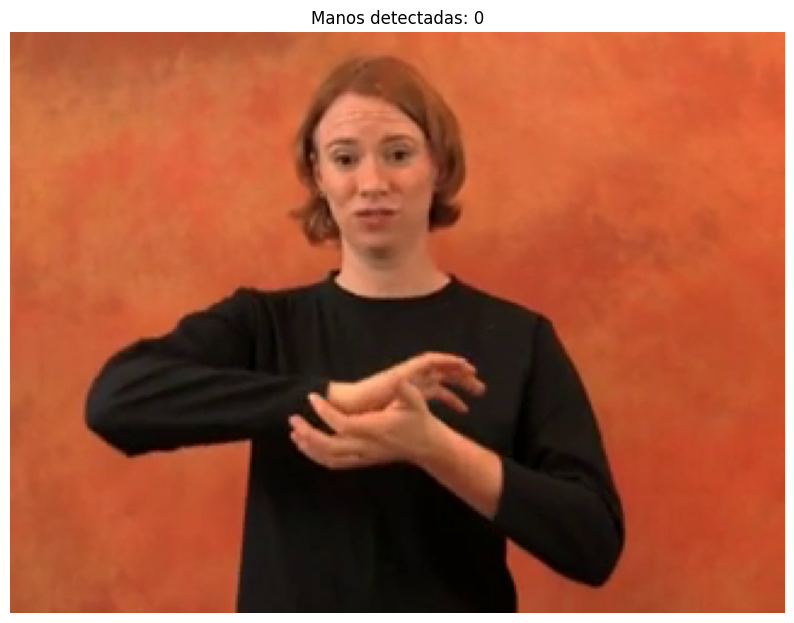

In [16]:
# ==========================================
# 5. PRUEBA RAPIDA DE DETECCION (Oficial Google)
# ==========================================

if len(frames) > 0:
    test_frame = frames[22]  # Frame RGB
    
    # PASO CRITICO: Crear mp.Image correctamente
    mp_image = mp.Image(image_format=mp.ImageFormat.SRGB, data=test_frame)
    
    # Detectar
    result = detector.detect(mp_image)
    
    # Ver resultados
    print(f"Manos detectadas: {len(result.hand_landmarks)}")
    
    if result.hand_landmarks:
        for i, (landmarks, handedness) in enumerate(zip(result.hand_landmarks, result.handedness)):
            print(f"  Mano {i+1}: {handedness[0].category_name}")
            print(f"    Landmarks: {len(landmarks)} puntos")
            for j in range(3):
                lm = landmarks[j]
                print(f"      [{j}] x={lm.x:.3f}, y={lm.y:.3f}, z={lm.z:.3f}")
    
    # Dibujar usando funcion oficial
    annotated = draw_landmarks_on_image(test_frame, result)
    
    plt.figure(figsize=(10, 8))
    plt.imshow(annotated)
    plt.title(f"Manos detectadas: {len(result.hand_landmarks)}")
    plt.axis('off')
    plt.show()
else:
    print("No hay frames cargados.")

In [7]:
# ==========================================
# 6. FUNCION DE EXTRACCION DE LANDMARKS
# ==========================================

def extract_landmarks(frame_rgb, hands_detector):
    """
    Extrae landmarks de un frame (numpy array RGB) usando Tasks API.
    
    Returns:
        all_landmarks: lista de arrays (21, 3), uno por mano detectada
        all_handedness: lista de strings ('Left' o 'Right')
    """
    # Conversion CRITICA para Tasks API
    mp_image = mp.Image(image_format=mp.ImageFormat.SRGB, data=frame_rgb)
    
    # Detectar
    detection_result = hands_detector.detect(mp_image)
    
    # Procesar resultados
    all_landmarks = []
    all_handedness = []
    
    if detection_result.hand_landmarks:
        for i, landmarks in enumerate(detection_result.hand_landmarks):
            coords = np.array([[lm.x, lm.y, lm.z] for lm in landmarks])
            all_landmarks.append(coords)
            
            if detection_result.handedness:
                label = detection_result.handedness[i][0].category_name
                all_handedness.append(label)
            else:
                all_handedness.append("Unknown")
    
    return all_landmarks, all_handedness

# Probar la funcion
landmarks, handedness = extract_landmarks(frames[0], detector)
print(f"Landmarks extraidos: {len(landmarks)} mano(s)")
if landmarks:
    print(f"  Shape: {landmarks[0].shape}")
    print(f"  Handedness: {handedness}")

Landmarks extraidos: 0 mano(s)


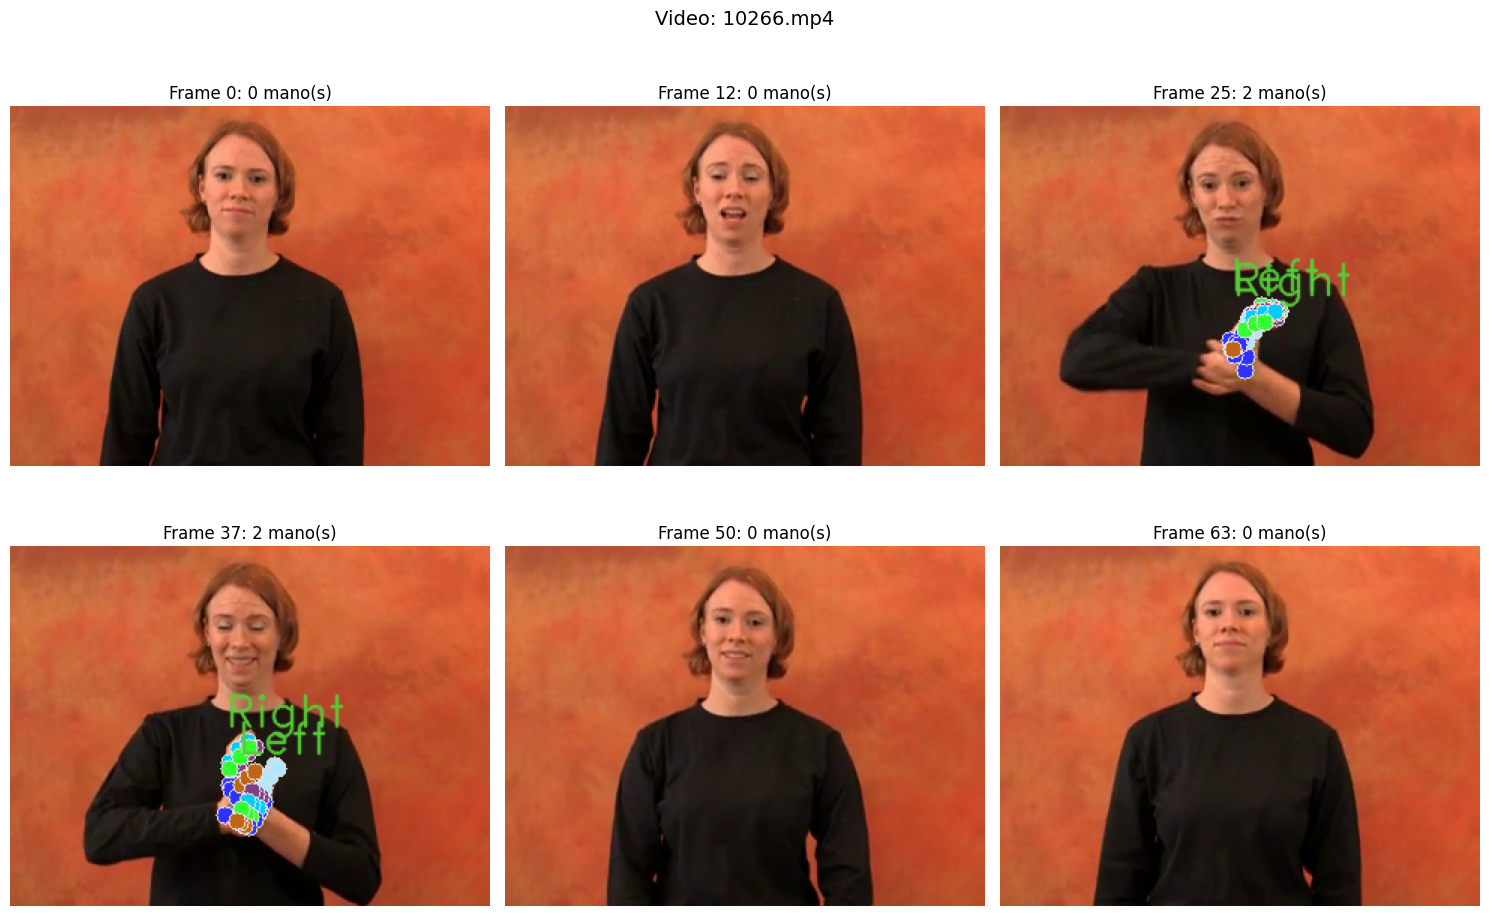


Estadisticas: 30/64 frames con manos (46.9%)


In [8]:
# ==========================================
# 7. VISUALIZAR MULTIPLES FRAMES
# ==========================================

num_samples = min(6, len(frames))
indices = np.linspace(0, len(frames)-1, num_samples, dtype=int)

fig, axes = plt.subplots(2, 3, figsize=(15, 10))
axes = axes.flatten()

for i, idx in enumerate(indices):
    frame = frames[idx]
    
    # Detectar
    mp_image = mp.Image(image_format=mp.ImageFormat.SRGB, data=frame)
    result = detector.detect(mp_image)
    
    # Dibujar
    annotated = draw_landmarks_on_image(frame, result)
    
    axes[i].imshow(annotated)
    axes[i].set_title(f"Frame {idx}: {len(result.hand_landmarks)} mano(s)")
    axes[i].axis('off')

plt.suptitle(f"Video: {sample_video.name}", fontsize=14)
plt.tight_layout()
plt.show()

# Estadisticas de deteccion
detected = 0
for frame in frames:
    mp_image = mp.Image(image_format=mp.ImageFormat.SRGB, data=frame)
    result = detector.detect(mp_image)
    if result.hand_landmarks:
        detected += 1

print(f"\nEstadisticas: {detected}/{len(frames)} frames con manos ({100*detected/len(frames):.1f}%)")

In [9]:
# ==========================================
# 8. EXTRAER LANDMARKS DE TODO EL VIDEO
# ==========================================

def extract_video_landmarks(frames, hands_detector):
    """
    Extrae landmarks para todos los frames de un video.
    
    Returns:
        video_landmarks: array (T, 21, 3)
        stats: diccionario con estadisticas
    """
    all_frame_landmarks = []
    stats = {'detected': 0, 'not_detected': 0}
    
    for frame in frames:
        landmarks, _ = extract_landmarks(frame, hands_detector)
        
        if landmarks:
            all_frame_landmarks.append(landmarks[0])
            stats['detected'] += 1
        else:
            all_frame_landmarks.append(np.zeros((21, 3)))
            stats['not_detected'] += 1
    
    return np.array(all_frame_landmarks), stats

video_landmarks, stats = extract_video_landmarks(frames, detector)

print(f"Shape de landmarks: {video_landmarks.shape}")
print(f"  = {video_landmarks.shape[0]} frames x {video_landmarks.shape[1]} landmarks x {video_landmarks.shape[2]} coords")
print(f"\nComparacion:")
print(f"  Imagen: 224x224x3 = {224*224*3:,} valores/frame")
print(f"  Landmarks: 21x3 = 63 valores/frame")
print(f"  Reduccion: {224*224*3 / 63:.0f}x menos datos!")
print(f"\nDeteccion: {stats}")

Shape de landmarks: (64, 21, 3)
  = 64 frames x 21 landmarks x 3 coords

Comparacion:
  Imagen: 224x224x3 = 150,528 valores/frame
  Landmarks: 21x3 = 63 valores/frame
  Reduccion: 2389x menos datos!

Deteccion: {'detected': 30, 'not_detected': 34}


In [10]:
# ==========================================
# 9. PROBAR CON VARIOS VIDEOS
# ==========================================

test_videos = list(RAW_VIDEOS_DIR.glob("*.mp4"))[:5]

print("Probando deteccion en varios videos...\n")

for video_path in test_videos:
    test_frames = load_frames_from_video(video_path, max_frames=10)
    
    detected_count = 0
    for frame in test_frames:
        mp_image = mp.Image(image_format=mp.ImageFormat.SRGB, data=frame)
        result = detector.detect(mp_image)
        if result.hand_landmarks:
            detected_count += 1
    
    rate = 100 * detected_count / len(test_frames)
    status = "OK" if rate > 50 else "BAJO"
    print(f"  {video_path.name}: {detected_count}/{len(test_frames)} ({rate:.0f}%) [{status}]\n")

Probando deteccion en varios videos...

Video: 10266.mp4
  Total frames: 76, FPS: 25.0
  Cargados: 10 frames, Shape: (240, 320, 3)
  10266.mp4: 4/10 (40%) [BAJO]

Video: 10972.mp4
  Total frames: 63, FPS: 30.0
  Cargados: 9 frames, Shape: (192, 288, 3)
  10972.mp4: 9/9 (100%) [OK]

Video: 54298.mp4
  Total frames: 78, FPS: 30.0
  Cargados: 10 frames, Shape: (480, 640, 3)
  54298.mp4: 7/10 (70%) [OK]

Video: 33805.mp4
  Total frames: 40, FPS: 30.0
  Cargados: 10 frames, Shape: (1080, 1920, 3)
  33805.mp4: 7/10 (70%) [OK]

Video: 20364.mp4
  Total frames: 69, FPS: 30.0
  Cargados: 10 frames, Shape: (720, 1280, 3)
  20364.mp4: 7/10 (70%) [OK]



In [17]:
# ==========================================
# 10. GENERAR VIDEO CON ESQUELETO (VISUALIZACIÓN)
# ==========================================
from IPython.display import HTML
from base64 import b64encode

def create_and_show_video(frames, detector, output_filename="output_skeleton.mp4", fps=25):
    """
    1. Procesa los frames.
    2. Dibuja el esqueleto.
    3. Guarda un MP4.
    4. Lo muestra en el notebook.
    """
    height, width, _ = frames[0].shape
    
    # Configurar VideoWriter (mp4v funciona bien en Linux)
    fourcc = cv2.VideoWriter_fourcc(*'mp4v') 
    out = cv2.VideoWriter(output_filename, fourcc, fps, (width, height))
    
    print(f"Generando video: {output_filename}...")
    
    for i, frame in enumerate(frames):
        # 1. Crear imagen MP
        mp_image = mp.Image(image_format=mp.ImageFormat.SRGB, data=frame)
        
        # 2. Detectar
        result = detector.detect(mp_image)
        
        # 3. Dibujar
        annotated_frame = draw_landmarks_on_image(frame, result)
        
        # 4. Convertir RGB -> BGR para OpenCV VideoWriter
        bgr_frame = cv2.cvtColor(annotated_frame, cv2.COLOR_RGB2BGR)
        out.write(bgr_frame)
        
        if i % 10 == 0:
            print(f".", end="")
            
    out.release()
    print("\n¡Video generado!")
    
    # 5. Mostrar en el Notebook
    mp4 = open(output_filename, 'rb').read()
    data_url = "data:video/mp4;base64," + b64encode(mp4).decode()
    
    return HTML(f"""
    <video width=600 controls>
          <source src="{data_url}" type="video/mp4">
    </video>
    """)

# --- EJECUTAR ---
# Usamos los frames que ya tienes cargados de un vídeo anterior
if len(frames) > 0:
    display(create_and_show_video(frames, detector, "demo_result.mp4"))
else:
    print("Carga primero unos frames en la variable 'frames'")

Generando video: demo_result.mp4...
.......
¡Video generado!


## Resumen

### Lo que MediaPipe nos da

| Aspecto | Basado en imagen | Basado en landmarks |
|---------|------------------|--------------------|
| Valores por frame | 150,528 | 63 |
| Contiene fondo | Si | No |
| Contiene color de piel | Si | No |
| Contiene iluminacion | Si | No |
| Riesgo de overfitting | Muy alto | Bajo |

### Proximos pasos

1. Procesar todos los videos WLASL con MediaPipe
2. Guardar landmarks como numpy arrays
3. Entrenar LSTM sobre landmarks
4. Comparar con enfoque basado en imagenes

In [11]:
# Limpiar recursos
detector.close()
print("Recursos de MediaPipe liberados.")

Recursos de MediaPipe liberados.
